In [ ]:
!pip install numpy matplotlib scikit-learn tensorflow

Loading MNIST dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data shape: (60000, 28, 28)
Testing data shape : (10000, 28, 28)


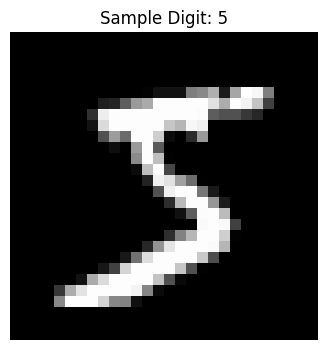


Training samples: 5000
Testing samples : 1000

Training KNN...
KNN Accuracy: 90.9 %

Training SVM...
SVM Accuracy: 93.6 %

Training Neural Network...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


Neural Network Accuracy: 92.3 %

       MODEL ACCURACY RESULTS
KNN             : 90.9 %
SVM             : 93.6 %
Neural Network  : 92.3 %


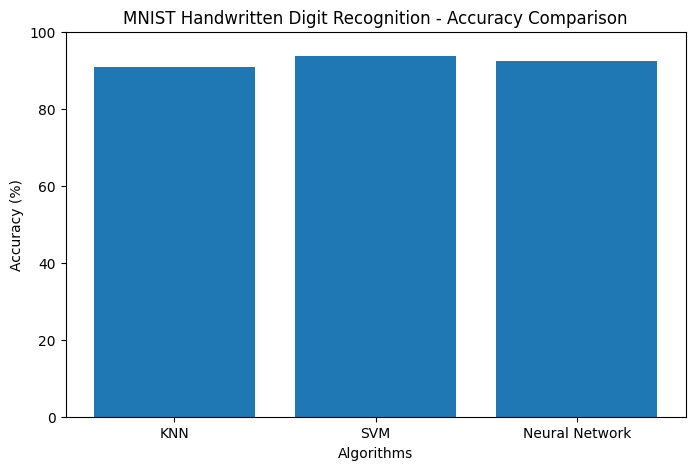

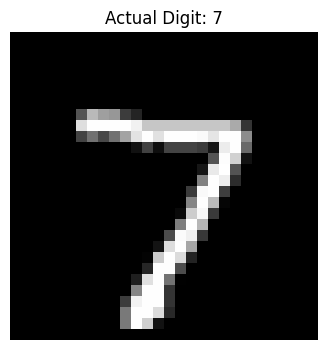


        DIGIT PREDICTION
Actual Digit       : 7
KNN Prediction     : 7
SVM Prediction     : 7
Neural Network     : 7


In [ ]:
# ============================================================
# HANDWRITTEN DIGIT RECOGNITION USING MNIST DATASET
# Algorithms: KNN, SVM and Neural Network
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


# ============================================================
# STEP 1: LOAD MNIST DATASET
# ============================================================

print("Loading MNIST dataset...")

(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape :", x_test.shape)


# ============================================================
# STEP 2: DISPLAY ONE IMAGE
# ============================================================

plt.figure(figsize=(4, 4))

plt.imshow(x_train[0], cmap="gray")

plt.title("Sample Digit: " + str(y_train[0]))

plt.axis("off")

plt.show()


# ============================================================
# STEP 3: FLATTEN THE IMAGES
# ============================================================

# Each image is 28 x 28 pixels.
# Convert it into 784 features.

x_train = x_train.reshape(x_train.shape[0], 784)
x_test = x_test.reshape(x_test.shape[0], 784)


# ============================================================
# STEP 4: NORMALIZE DATA
# ============================================================

# Pixel values are between 0 and 255.
# Convert them to values between 0 and 1.

x_train = x_train / 255.0
x_test = x_test / 255.0


# ============================================================
# STEP 5: SELECT SMALLER DATASET
# ============================================================

# Using fewer samples makes the program faster.

x_train_small = x_train[:5000]
y_train_small = y_train[:5000]

x_test_small = x_test[:1000]
y_test_small = y_test[:1000]

print("\nTraining samples:", len(x_train_small))
print("Testing samples :", len(x_test_small))


# ============================================================
# STEP 6: CREATE KNN MODEL
# ============================================================

print("\nTraining KNN...")

knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(x_train_small, y_train_small)

knn_pred = knn.predict(x_test_small)

knn_accuracy = accuracy_score(
    y_test_small,
    knn_pred
)

print(
    "KNN Accuracy:",
    round(knn_accuracy * 100, 2),
    "%"
)


# ============================================================
# STEP 7: CREATE SVM MODEL
# ============================================================

print("\nTraining SVM...")

svm = SVC(kernel="rbf")

svm.fit(x_train_small, y_train_small)

svm_pred = svm.predict(x_test_small)

svm_accuracy = accuracy_score(
    y_test_small,
    svm_pred
)

print(
    "SVM Accuracy:",
    round(svm_accuracy * 100, 2),
    "%"
)


# ============================================================
# STEP 8: CREATE NEURAL NETWORK MODEL
# ============================================================

print("\nTraining Neural Network...")

neural_network = MLPClassifier(
    hidden_layer_sizes=(128,),
    activation="relu",
    solver="adam",
    max_iter=20,
    random_state=42
)

neural_network.fit(
    x_train_small,
    y_train_small
)

nn_pred = neural_network.predict(
    x_test_small
)

nn_accuracy = accuracy_score(
    y_test_small,
    nn_pred
)

print(
    "Neural Network Accuracy:",
    round(nn_accuracy * 100, 2),
    "%"
)


# ============================================================
# STEP 9: COMPARE ALL ALGORITHMS
# ============================================================

print("\n====================================")
print("       MODEL ACCURACY RESULTS")
print("====================================")

print(
    "KNN             :",
    round(knn_accuracy * 100, 2),
    "%"
)

print(
    "SVM             :",
    round(svm_accuracy * 100, 2),
    "%"
)

print(
    "Neural Network  :",
    round(nn_accuracy * 100, 2),
    "%"
)


# ============================================================
# STEP 10: ACCURACY GRAPH
# ============================================================

models = [
    "KNN",
    "SVM",
    "Neural Network"
]

accuracies = [
    knn_accuracy * 100,
    svm_accuracy * 100,
    nn_accuracy * 100
]

plt.figure(figsize=(8, 5))

plt.bar(
    models,
    accuracies
)

plt.xlabel("Algorithms")

plt.ylabel("Accuracy (%)")

plt.title(
    "MNIST Handwritten Digit Recognition - Accuracy Comparison"
)

plt.ylim(0, 100)

plt.show()


# ============================================================
# STEP 11: TEST A SAMPLE DIGIT
# ============================================================

index = 0

sample = x_test_small[index]

actual_digit = y_test_small[index]


# Predictions from all models

knn_result = knn.predict(
    sample.reshape(1, -1)
)[0]

svm_result = svm.predict(
    sample.reshape(1, -1)
)[0]

nn_result = neural_network.predict(
    sample.reshape(1, -1)
)[0]


# ============================================================
# STEP 12: DISPLAY SAMPLE AND PREDICTIONS
# ============================================================

plt.figure(figsize=(4, 4))

plt.imshow(
    sample.reshape(28, 28),
    cmap="gray"
)

plt.title(
    "Actual Digit: " + str(actual_digit)
)

plt.axis("off")

plt.show()


print("\n====================================")
print("        DIGIT PREDICTION")
print("====================================")

print("Actual Digit       :", actual_digit)

print("KNN Prediction     :", knn_result)

print("SVM Prediction     :", svm_result)

print("Neural Network     :", nn_result)